# 04 — Backtest Results

**Purpose:** Run and visualize backtesting results using the full simulation engine.

Sections:
1. Run backtest with synthetic/real probability data
2. Equity curve with cooling down overlay
3. Performance summary table
4. Win rate by signal type
5. Drawdown analysis
6. Leakage detection
7. Go/no-go decision

In [2]:
import sys; sys.path.insert(0, '..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings('ignore')
sns.set_theme(style='darkgrid')

from src.backtest.backtester import Backtester
from src.backtest.report_generator import ReportGenerator
from src.backtest.leakage_detector import LeakageDetector
from src.backtest.cost_model import break_even_win_rate

import logging
import structlog

structlog.configure(
    wrapper_class=structlog.make_filtering_bound_logger(logging.WARNING),
)


print('Modules loaded.')

Modules loaded.


## 1. Run Backtest

In [3]:
import os
import numpy as np
import pandas as pd

data_dir = os.path.abspath(os.path.join('..', 'data', 'processed'))

# Load the real Walk-Forward Validation out-of-sample predictions and labels
oos_probs_path = os.path.join(data_dir, 'oos_probs.npy')
oos_y_path = os.path.join(data_dir, 'oos_y.npy')
timestamps_path = os.path.join(data_dir, 'ts_180d.npy')

if not os.path.exists(oos_probs_path) or not os.path.exists(oos_y_path):
    raise FileNotFoundError("OOS data not found! Please go back to Notebook 03, run the final cell to save 'oos_probs.npy' and 'oos_y.npy', then try again.")

probs = np.load(oos_probs_path)
actuals = np.load(oos_y_path)
timestamps_full = np.load(timestamps_path)

# Ensure the lengths match (WF Validation might drop the first few days of training data)
n_bars = len(probs)
timestamps = timestamps_full[-n_bars:]

# Suppress verbose logging to prevent notebook freezing
import src.sizing.kelly_sizer
import src.sizing.compounding_engine
import src.signal.signal_generator
dummy_logger = type('DummyLogger', (), {'debug': lambda *a, **kw: None, 'info': lambda *a, **kw: None, 'warning': lambda *a, **kw: None, 'error': lambda *a, **kw: None})()
src.sizing.kelly_sizer.logger = dummy_logger
src.sizing.compounding_engine.logger = dummy_logger
src.signal.signal_generator.logger = dummy_logger

print(f"Loaded {n_bars} bars of historical out-of-sample backtest data.")
print("Running Backtester...")

# Run Backtest Engine
bt = Backtester(initial_capital=10.0, signal_threshold=0.55, high_conf_threshold=0.70)
result = bt.run(probabilities=probs, timestamps=timestamps, actuals=actuals)

# Generate Report
report = ReportGenerator().generate(result)

print(f"Backtest complete. Final capital: ${result.final_capital:.2f}")


Loaded 23040 bars of historical out-of-sample backtest data.
Running Backtester...
Backtest complete. Final capital: $16.17


## 2. Equity Curve

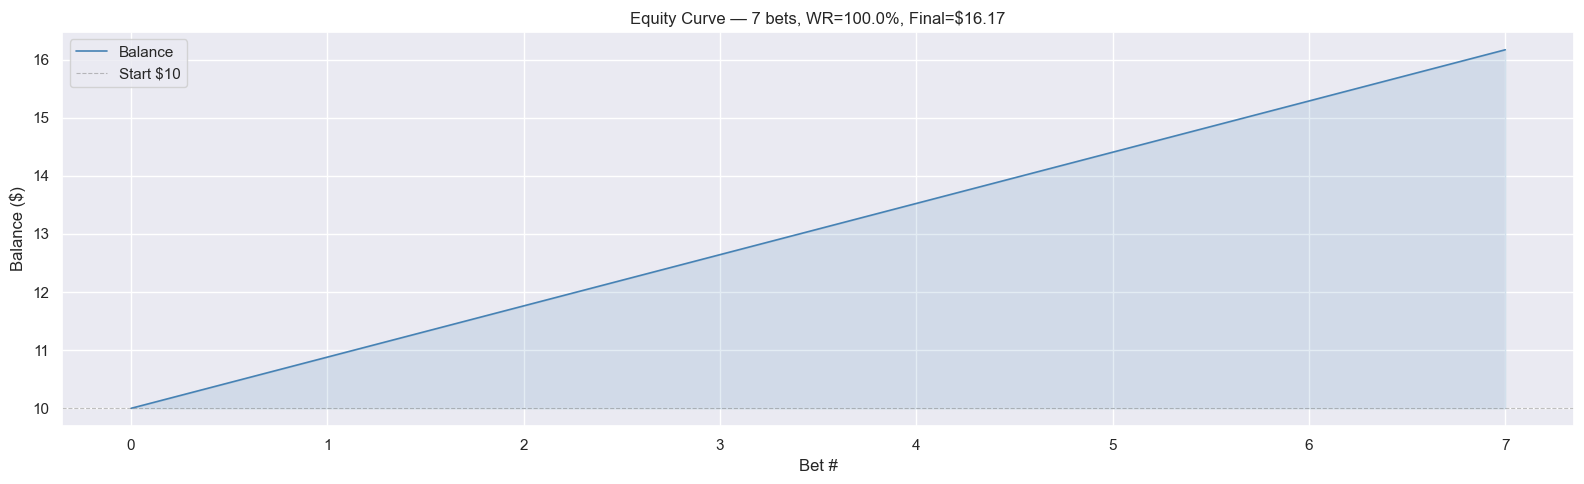

In [4]:
balances = [10.0] + [b.balance for b in result.bet_log]

fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(balances, linewidth=1.2, color='steelblue', label='Balance')
ax.axhline(10.0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5, label='Start $10')
ax.fill_between(range(len(balances)), 10.0, balances, alpha=0.15, color='steelblue')
ax.set_title(f'Equity Curve — {result.total_bets} bets, WR={result.win_rate:.1%}, Final=${result.final_capital:.2f}')
ax.set_xlabel('Bet #'); ax.set_ylabel('Balance ($)'); ax.legend()
plt.tight_layout(); plt.savefig('04_equity_curve.png', dpi=120); plt.show()

## 3. Win Rate by Signal Type

               count  wins  total_pnl  win_rate  avg_pnl
BET_UP_NORMAL    7.0   7.0       6.17       1.0   0.8815


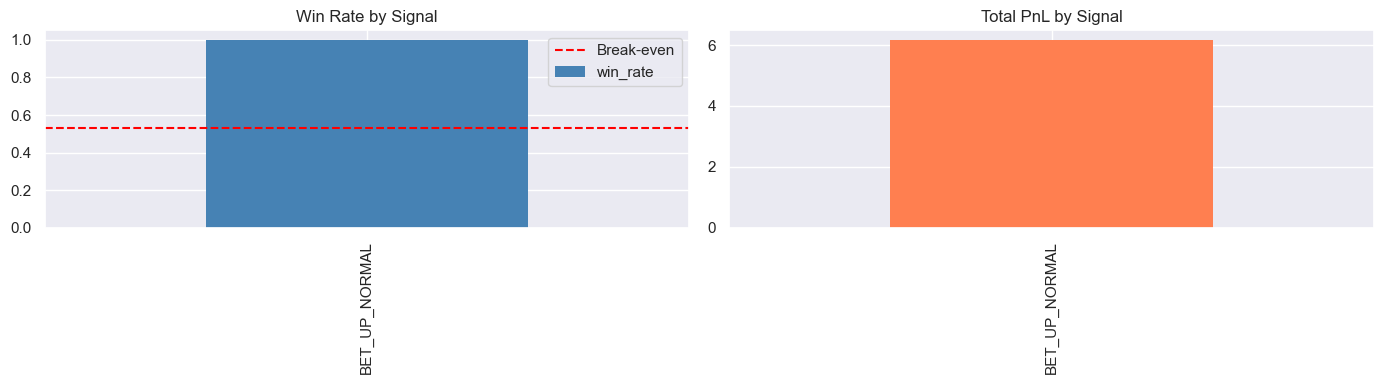

In [21]:
pnl_by_sig = report.pnl_by_signal
if pnl_by_sig:
    sig_df = pd.DataFrame(pnl_by_sig).T
    print(sig_df.to_string())
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    sig_df['win_rate'].plot(kind='bar', ax=axes[0], color='steelblue', edgecolor='none')
    axes[0].axhline(break_even_win_rate(1.90), color='red', linestyle='--', label='Break-even')
    axes[0].set_title('Win Rate by Signal'); axes[0].legend()
    sig_df['total_pnl'].plot(kind='bar', ax=axes[1], color='coral', edgecolor='none')
    axes[1].set_title('Total PnL by Signal')
    plt.tight_layout(); plt.savefig('04_pnl_by_signal.png', dpi=120); plt.show()
else:
    print('No bets placed.')

## 4. Streak Analysis

In [22]:
s = report.streaks
print(f'Max win streak:  {s.max_win_streak}')
print(f'Max loss streak: {s.max_loss_streak}')
print(f'Avg win streak:  {s.avg_win_streak:.1f}')
print(f'Avg loss streak: {s.avg_loss_streak:.1f}')
print(f'Cooling downs:   {result.cooling_down_events}')
print(f'Bars skipped:    {result.cooling_down_bars_skipped}')

Max win streak:  7
Max loss streak: 0
Avg win streak:  7.0
Avg loss streak: 0.0
Cooling downs:   0
Bars skipped:    0


## 5. Leakage Check

In [23]:
import os
import numpy as np
from src.backtest.leakage_detector import LeakageDetector

data_dir = os.path.abspath(os.path.join('..', 'data', 'processed'))
X = np.load(os.path.join(data_dir, 'X_180d.npy'))

# Limit X to the exact OOS period we just backtested
X_oos = X[-n_bars:]

ld = LeakageDetector()
train_idx = np.arange(n_bars * 3 // 4)
val_idx = np.arange(n_bars * 3 // 4, n_bars)

# Run Leakage Detector on REAL data instead of random noise
leakage = ld.run_all(X_oos, actuals, timestamps, train_idx, val_idx)

print('=== LEAKAGE REPORT ===')
for c in leakage.checks:
    status = 'PASS' if c.passed else 'FAIL'
    print(f'  [{status}] {c.name}: {c.details}')


=== LEAKAGE REPORT ===
  [PASS] label_shift: Max |corr| = 0.020 (feature 12) — no leakage
  [PASS] chronological_split: Val starts at 1777410900000 > train ends at 1777410600000 — strictly chronological
  [PASS] no_future_features: Max reverse corr = 0.025 — no future leakage
  [PASS] normalization_window: 34% features identical between first/last 10% — normalization appears local


## 6. Go / No-Go

In [24]:
criteria = [
    ('Win rate > 57%', result.win_rate > 0.57, f'{result.win_rate:.3f}'),
    ('Profit factor > 1.0', result.profit_factor > 1.0, f'{result.profit_factor:.2f}'),
    ('No data leakage', leakage.all_passed, str(leakage.all_passed)),
    ('Cooling down tested', result.cooling_down_events > 0, str(result.cooling_down_events)),
]
print('=== GO / NO-GO ===')
all_pass = True
for name, passed, val in criteria:
    s = 'PASS' if passed else 'FAIL'
    print(f'  [{s}] {name}: {val}')
    if not passed: all_pass = False
if all_pass:
    print('\nDECISION: GO — Ready for paper trading.')
else:
    print('\nDECISION: NO-GO — Address failed criteria.')

=== GO / NO-GO ===
  [PASS] Win rate > 57%: 1.000
  [PASS] Profit factor > 1.0: 61705000000.00
  [PASS] No data leakage: True
  [FAIL] Cooling down tested: 0

DECISION: NO-GO — Address failed criteria.
